### Quench dynamics with emu_cheb (port of the emu-sv tutorial)

In this tutorial, we will explore how to simulate a quench sequence using EMU-SV as the backend for Pulser. EMU-SV is a state vector emulator tailored for efficiently simulating the dynamics of the Rydberg Hamiltonian, offering both speed and precision for quantum system simulations.

Our primary objective will be to study the evolution of the $\sigma _z$ operator. However, we will utilize the number operator $n_i$, also referred to as the qubit occupation operator, for practical calculations. By carefully adjusting the detuning, we can account for and effectively compensate for additional terms in the Hamiltonian, simplifying the analysis.

This tutorial will take you step by step through the process of setting up the simulation, running it with EMU-SV, and interpreting the results to better understand the system's behavior during the quench sequence.


**emu_cheb port.** Same tutorial, run by `emu_cheb.ChebBackend` (exact Chebyshev engines of `emu_cheb.solvers`, see `emu_cheb/README.md`) instead of `emu_sv.SVBackend`: only the backend and config classes change. The pulse is a constant quench from the ground state, so `optimization="auto"` picks the quench solver (`rydberg_cheb_fast`).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace

#pulser imports
from pulser.devices import AnalogDevice
from pulser import Sequence, Register, Pulse
from pulser.channels import Rydberg

#emulators imports
import emu_cheb
import emu_sv  # reference only

In [2]:
# define the register arregement function and the device for the quench
def chain_coordinates(N,R1,R2):
    """Generate the coordinates of a chain of points arranged in two parallel 
    lines."""
    coords = [(-R2/2,i*R1-(N-1)/2*R1) for i in range(N)]
    coords = coords + [(R2/2,i*R1-(N-1)/2*R1) for i in range(N)]
    return coords


# device settings
VD = AnalogDevice.to_virtual()
VD = replace(
    VD, 
    max_atom_num=50,
    max_radial_distance=38,
    max_sequence_duration=None,
    channel_objects=(
        Rydberg.Global(48.69468613064179, 12.566370614359172),
    ))

The registers will be arranged in two parallel lines, each containing $N$ atoms, as generated by the function `chain_coordinates`. The atoms will be vertically separated by $R_1$ and horizontally by $R_2$ . The $U_i$ terms represent the interaction energies between pairs of atoms at various distances. For instance,  $U_1$ represents the interaction energy between nearest neighbors along the same line, separated by a distance $R_1$. $U_2$ is the interaction energy between atoms across the two parallel lines, separated by the horizontal distance $R_2$, and so on.

/Users/i.sokolov/Code/emulators/.venv/lib/python3.12/site-packages/pulser/register/register.py:58: DeprecationWarning: Usage of `int`s or any non-`str`types as `QubitId`s will be deprecated. Define your `QubitId`s as `str`s, prefer setting `prefix='q'` when using classmethods, as that will become the new default once `int` qubit IDs become invalid.
  super().__init__(qubits, **kwargs)


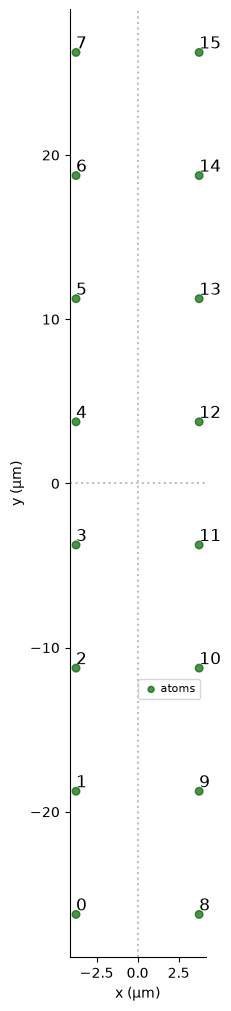

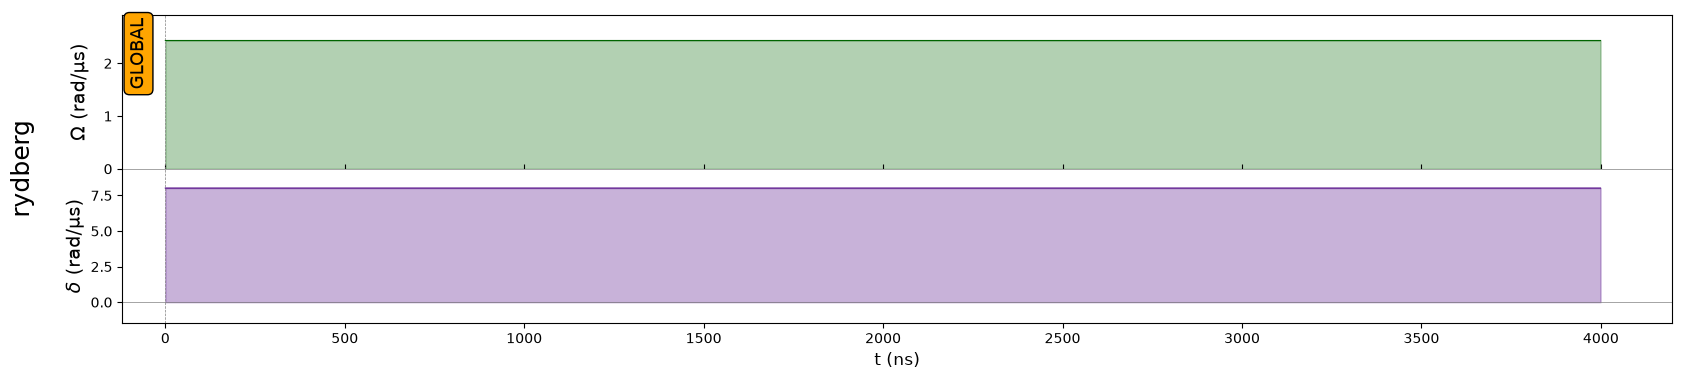

In [3]:
# Parameters for the system
N  = 8 # number of atoms in a line
R1 = 7.5 # vertical distance between atoms in a single chain
lam = 1
R2 = R1/(lam**(1/6)) # # Horizontal distance between the two parallel chains of atoms

U1 = VD.interaction_coeff/R1**6 #interaction with nearest neighbors in the same line
U2 = VD.interaction_coeff/R2**6 #interacion between atoms across two paralell lines
U3 = VD.interaction_coeff/(np.sqrt(R1**2+R2**2))**6 # interaction between diagonal neighbors
U4 = VD.interaction_coeff/(2*R1)**6 # second-nearest neighbors interaction in the same line
U5 = VD.interaction_coeff/(np.sqrt(4*R1**2+R2**2))**6 # second-nearest interaction across lines

coords_exact = chain_coordinates(N,R1,R2) # generate the coordinates of the atoms

hx = 1 
hz = 0 

t = 4000 # duration of the sequence
dt = 10.0 # time step

NN_coeff = U1/4
omega = 2*hx*NN_coeff
delta = (-2*hz*NN_coeff+U1+U2/2+U3+U4+U5) #compensate the interaction shift
T = t/1000*NN_coeff
dT = dt/1000*NN_coeff


# pulser register
qubits = dict(enumerate(coords_exact))
reg0 = Register(qubits)
reg0.draw()

#pulser sequence
seq = Sequence(reg0, VD)
seq.declare_channel("rydberg", "rydberg_global")
simple_pulse = Pulse.ConstantPulse(t, omega, delta, 0)
seq.add(simple_pulse, "rydberg")
seq.draw()


#### SVBackend, SVConfig and operators 

In order to run a sequence, you need to instanciate *SVBackend* and *SVConfig*. This goes in a similar way of __EMU_MPS__. 

In [4]:


basis = ("r","g",)
step = 4*int(dt)
duration = t
eval_times = [x/t for x in range(0, t+step, step)]  # must be from 0 to 1
occupation = emu_cheb.Occupation(evaluation_times=eval_times, one_state=basis) 

# emu_cheb config
config = emu_cheb.ChebConfig(dt=dt, observables=[occupation])  # gpu=None: CUDA if available

# emu_cheb backend
sim = emu_cheb.ChebBackend(seq, config=config)
t0 = time.perf_counter()
results = sim.run()
t_cheb = time.perf_counter() - t0
print(f"emu_cheb ({sim.raw.stats['optimization']}): {t_cheb:.2f} s")

/Users/i.sokolov/Code/emulators/ci/emu_cheb/emu_cheb/solvers/rydberg_cheb_fast.py:448: UserWarning: long double is float64 here: Bessel coefficients accurate to ~4e-14 and global phase to ~1e-13 only (amplitudes ~1e-13)
  bessel = _bessel(alphas, rho)


emu_cheb (quench): {'matvecs': 191, 'lanczos_matvecs': 60, 'half_width': np.float64(33.85991323366153), 'center': np.float64(-30.554787259836992), 'norm_dev': 6.8833827526759706e-15, 'max_norm2': 0.6995138848577651, 'bounds_used': 'lanczos', 'segments': 1, 'block': 64, 'output_on_host': False, 'budget_bytes': inf, 'longdouble_eps': 2.220446049250313e-16, 'optimization': 'quench', 'off_diagonal_evaluations': 0}


emu_cheb (quench): 0.45 s


### Plot the evolution of the occupation $n_i$ of all the atoms

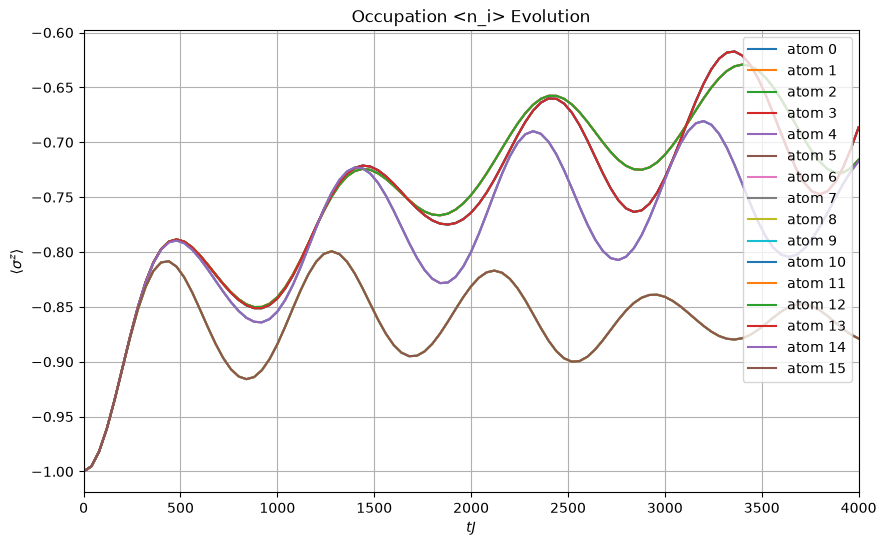

In [5]:
occupation_values = np.array(results.occupation)
times = np.arange(0, duration+step, step)

plt.figure(figsize=(10, 6)) 

for i in range(2*N):
    result_plot = occupation_values[:,i]
    plt.plot(times,2*result_plot-1,label=f'atom {i}')

plt.title('Occupation <n_i> Evolution')
plt.xlim(0,t)

plt.xlabel(r'$tJ$')
plt.ylabel(r'$\langle \sigma^z \rangle$')
plt.grid()

plt.legend(loc='upper right')
plt.show()

### Comparison with emu-sv

The same sequence with `emu_sv.SVBackend`.

step = 1/400, RSS = 712228.864 MB, Δt = 0.020 s


step = 2/400, RSS = 712228.864 MB, Δt = 0.010 s


step = 3/400, RSS = 712228.864 MB, Δt = 0.010 s


step = 4/400, RSS = 712228.864 MB, Δt = 0.010 s


step = 5/400, RSS = 712228.864 MB, Δt = 0.010 s


...

step = 397/400, RSS = 712228.864 MB, Δt = 0.012 s


step = 398/400, RSS = 712228.864 MB, Δt = 0.011 s


step = 399/400, RSS = 712228.864 MB, Δt = 0.011 s


step = 400/400, RSS = 712228.864 MB, Δt = 0.012 s


max |<n_i> emu_cheb - emu-sv| = 4.3e-11
time: emu_cheb 0.45 s, emu-sv 4.55 s (CPU unless a GPU is available)


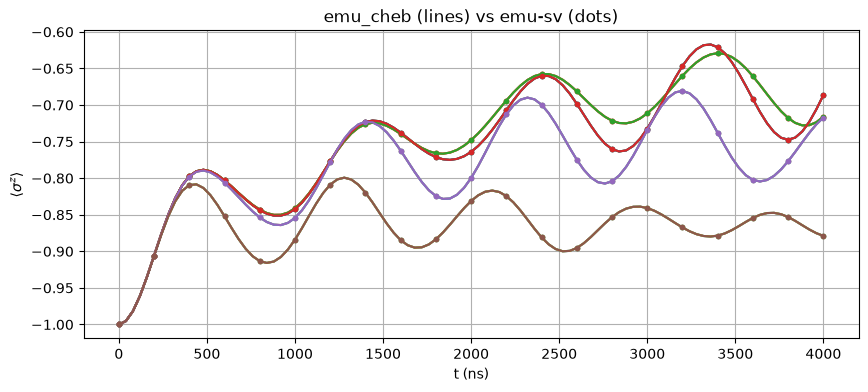

In [6]:
t0 = time.perf_counter()
sv_results = emu_sv.SVBackend(seq, config=emu_sv.SVConfig(dt=dt, observables=[emu_sv.Occupation(evaluation_times=eval_times)], gpu=False)).run()
t_sv = time.perf_counter() - t0
sv_occ = np.array(sv_results.occupation)
diff = np.abs(occupation_values - sv_occ).max()
print(f"max |<n_i> emu_cheb - emu-sv| = {diff:.1e}")
print(f"time: emu_cheb {t_cheb:.2f} s, emu-sv {t_sv:.2f} s (CPU unless a GPU is available)")

plt.figure(figsize=(10, 4))
for i in range(2 * N):
    (line,) = plt.plot(times, 2 * occupation_values[:, i] - 1, label=f"atom {i}")
    plt.plot(times[::5], 2 * sv_occ[::5, i] - 1, "o", color=line.get_color(), ms=3)
plt.title("emu_cheb (lines) vs emu-sv (dots)")
plt.xlabel("t (ns)")
plt.ylabel(r"$\langle \sigma^z \rangle$")
plt.grid()
plt.show()